In [1]:
import sys
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)
print("NumPy version:", np.__version__)

c:\Users\pranu1234\Documents\IoT-IDS\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.52.0
NumPy version: 2.5.3


In [2]:
import sys
sys.path.append("../src")

from model import Attention
from tensorflow.keras.models import load_model

model = load_model(
    "../models/cnn_lstm_attention_final.keras",
    custom_objects={"Attention": Attention}
)

print("Model loaded successfully!")
print("Input shape :", model.input_shape)
print("Output shape:", model.output_shape)


Model loaded successfully!
Input shape : (None, 5, 39)
Output shape: (None, 34)


In [3]:
from pathlib import Path

PROCESSED_DIR = Path("../data/CICIoT2023/processed")

X_test_sequences = np.load(
    PROCESSED_DIR / "X_test_sequences.npy"
)

y_test_sequences = np.load(
    PROCESSED_DIR / "y_test_sequences.npy"
)

print("X_test_sequences:", X_test_sequences.shape)
print("y_test_sequences:", y_test_sequences.shape)


X_test_sequences: (142459, 5, 39)
y_test_sequences: (142459,)


In [4]:
X_train_sequences = np.load(
    PROCESSED_DIR / "X_train_sequences.npy"
)

shap_background = X_train_sequences[:50]

print("SHAP background shape:", shap_background.shape)

SHAP background shape: (50, 5, 39)


In [5]:
shap_test = X_test_sequences[:1]

print("SHAP test sample shape:", shap_test.shape)

SHAP test sample shape: (1, 5, 39)


In [6]:
background_flat = shap_background.reshape(
    shap_background.shape[0], -1
)

test_flat = shap_test.reshape(
    shap_test.shape[0], -1
)

print("Background shape:", background_flat.shape)
print("Test shape      :", test_flat.shape)

Background shape: (50, 195)
Test shape      : (1, 195)


In [7]:
def model_predict_flattened(X_flat):
    X_sequence = X_flat.reshape(-1, 5, 39)
    return model.predict(X_sequence, verbose=0)

print("Prediction wrapper created successfully!")

Prediction wrapper created successfully!


In [8]:
explainer = shap.KernelExplainer(
    model_predict_flattened,
    background_flat
)

print("Kernel SHAP explainer created successfully!")

Kernel SHAP explainer created successfully!


In [9]:
shap_values = explainer.shap_values(
    test_flat,
    nsamples=100,
    ranked_outputs=1
)

print("SHAP values calculated successfully!")

100%|██████████| 1/1 [00:00<00:00,  1.16it/s]

SHAP values calculated successfully!


In [11]:
label_mapping = pd.read_csv(
    "../results/metrics/label_mapping.csv"
)

print("Label mapping loaded successfully!")
print("Number of classes:", len(label_mapping))

Label mapping loaded successfully!
Number of classes: 34


In [12]:
prediction = model.predict(shap_test, verbose=0)

predicted_class = np.argmax(prediction[0])

predicted_name = label_mapping.loc[
    label_mapping["encoded_id"] == predicted_class,
    "label"
].iloc[0]

print("Predicted class ID:", predicted_class)
print("Predicted attack  :", predicted_name)
print("Confidence        :", prediction[0][predicted_class])

Predicted class ID: 9
Predicted attack  : DDOS-RSTFINFLOOD
Confidence        : 0.99929893


In [14]:
shap_array = shap_values[0]

# Select SHAP values for the predicted class
shap_array = shap_array[:, predicted_class]

# 195 features → 5 timesteps × 39 original features
shap_array = shap_array.reshape(5, 39)

feature_shap = np.mean(
    np.abs(shap_array),
    axis=0
)

print("Feature SHAP shape:", feature_shap.shape)

Feature SHAP shape: (39,)


In [15]:
feature_names_df = pd.read_csv(
    "../results/metrics/feature_names.csv"
)

feature_names = feature_names_df.iloc[:, 0].tolist()

print("Number of feature names:", len(feature_names))
print(feature_names)

Number of feature names: 39
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38]


In [16]:
csv_path = "../data/CICIoT2023/raw/MERGED_CSV/MERGED_CSV/Merged01.csv"

feature_names = pd.read_csv(
    csv_path,
    nrows=0
).columns.drop("Label").tolist()

print("Number of feature names:", len(feature_names))
print(feature_names)

Number of feature names: 39
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance']


In [17]:
shap_df = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": feature_shap
})

shap_df = shap_df.sort_values(
    "SHAP_Value",
    ascending=False
).reset_index(drop=True)

print("Top 10 SHAP features:")
print(shap_df.head(10))

Top 10 SHAP features:
           Feature  SHAP_Value
0  fin_flag_number    0.073186
1        fin_count    0.053176
2  psh_flag_number    0.024392
3            HTTPS    0.016236
4          Tot sum    0.011046
5              IPv    0.009993
6        syn_count    0.004285
7        rst_count    0.000470
8  syn_flag_number    0.000000
9  rst_flag_number    0.000000


In [18]:
shap_df.to_csv(
    "../results/metrics/shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance saved successfully!")

SHAP feature importance saved successfully!


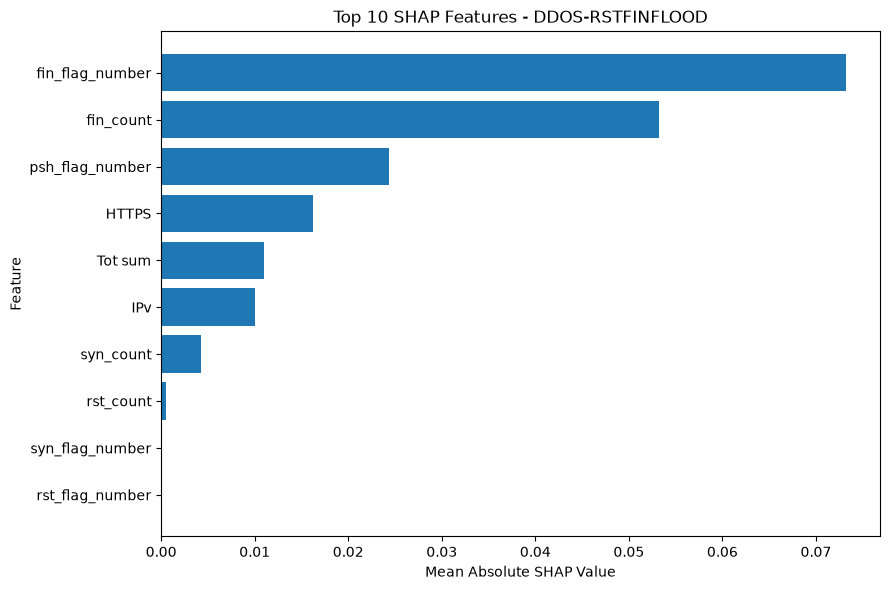

SHAP feature importance plot saved successfully!


In [19]:
top10 = shap_df.head(10).sort_values(
    "SHAP_Value",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top10["Feature"],
    top10["SHAP_Value"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title(
    f"Top 10 SHAP Features - {predicted_name}"
)

plt.tight_layout()

plt.savefig(
    "../results/figures/final_shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP feature importance plot saved successfully!")

In [20]:
print("Predicted Attack :", predicted_name)
print("Confidence       :", prediction[0][predicted_class])
print("\nTop 10 SHAP Features:")
print(shap_df.head(10).to_string(index=False))

Predicted Attack : DDOS-RSTFINFLOOD
Confidence       : 0.99929893

Top 10 SHAP Features:
        Feature  SHAP_Value
fin_flag_number    0.073186
      fin_count    0.053176
psh_flag_number    0.024392
          HTTPS    0.016236
        Tot sum    0.011046
            IPv    0.009993
      syn_count    0.004285
      rst_count    0.000470
syn_flag_number    0.000000
rst_flag_number    0.000000


## SHAP-Based Explainability Analysis

### Objective

SHAP (SHapley Additive exPlanations) was used to investigate how traffic features contributed to an individual intrusion-detection prediction.

### Experimental Setup

KernelExplainer was used to estimate feature contributions for a selected prediction. A background sample of 50 sequences and 100 SHAP samples were used in the experiment.

### Observations

For the examined prediction, the leading features included `fin_flag_number`, `fin_count`, `psh_flag_number`, `HTTPS`, `Tot sum`, `IPv`, `syn_count`, `rst_count`, `syn_flag_number`, and `rst_flag_number`.

These features contributed to the explanation of the selected prediction. Their SHAP contribution magnitudes describe the influence of features on that particular prediction; they should not be interpreted as percentages of overall model accuracy.

### Limitations

The current explanation represents an individual prediction rather than a complete global explanation of all attack classes. Further analysis across multiple correctly and incorrectly classified samples is needed to understand the model's broader behaviour.

In [1]:
import os

paths_to_check = [
    "../results/metrics/shap_feature_importance.csv",
    "../results/explanations",
    "../results/figures"
]

for path in paths_to_check:
    print(f"{path}: {'Exists' if os.path.exists(path) else 'Not found'}")

../results/metrics/shap_feature_importance.csv: Exists
../results/explanations: Not found
../results/figures: Exists


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../results/explanations", exist_ok=True)

shap_df = pd.read_csv(
    "../results/metrics/shap_feature_importance.csv"
)

print("SHAP CSV columns:", shap_df.columns.tolist())
display(shap_df.head(10))

SHAP CSV columns: ['Feature', 'SHAP_Value']


,Feature,SHAP_Value
0,fin_flag_number,0.073186
1,fin_count,0.053176
2,psh_flag_number,0.024392
3,HTTPS,0.016236
4,Tot sum,0.011046
5,IPv,0.009993
6,syn_count,0.004285
7,rst_count,0.000470
8,syn_flag_number,0.000000
9,rst_flag_number,0.000000


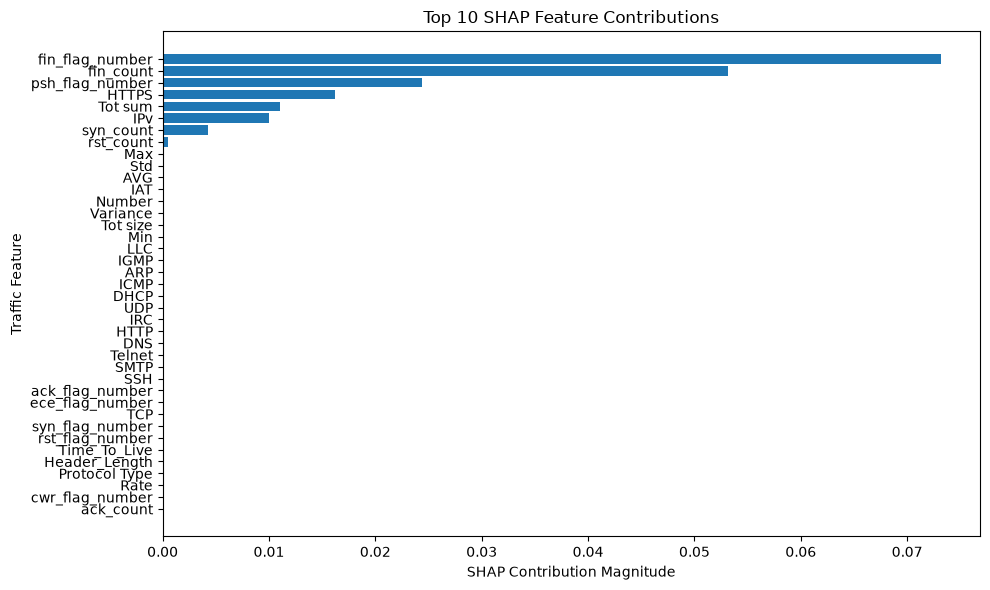

SHAP graph saved successfully!


In [3]:
shap_plot_df = shap_df.sort_values(
    "SHAP_Value",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    shap_plot_df["Feature"],
    shap_plot_df["SHAP_Value"]
)
plt.xlabel("SHAP Contribution Magnitude")
plt.ylabel("Traffic Feature")
plt.title("Top 10 SHAP Feature Contributions")
plt.tight_layout()

plt.savefig(
    "../results/figures/shap_top10_feature_contributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP graph saved successfully!")

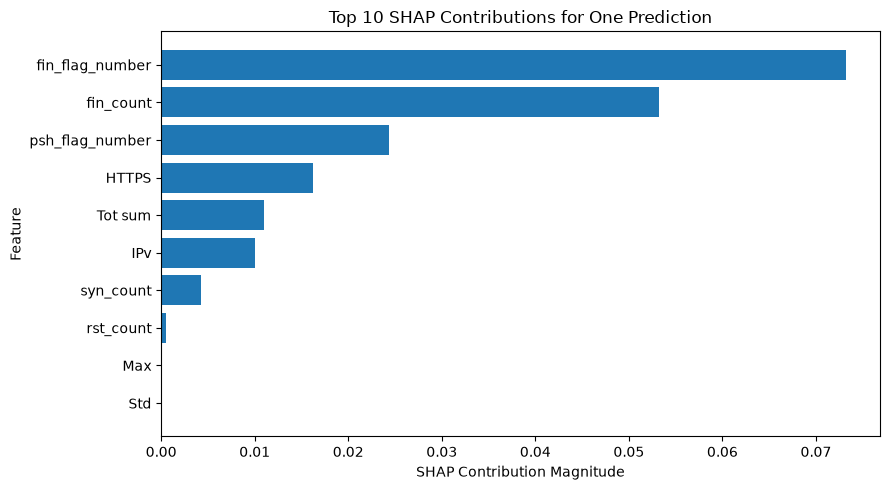

Corrected SHAP graph saved successfully!


In [4]:
top10_shap = shap_df.sort_values(
    "SHAP_Value",
    ascending=True
).tail(10)

plt.figure(figsize=(9, 5))
plt.barh(
    top10_shap["Feature"],
    top10_shap["SHAP_Value"]
)
plt.xlabel("SHAP Contribution Magnitude")
plt.ylabel("Feature")
plt.title("Top 10 SHAP Contributions for One Prediction")
plt.tight_layout()

plt.savefig(
    "../results/figures/shap_top10_feature_contributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Corrected SHAP graph saved successfully!")

### SHAP-Based Explainability Results

SHAP (SHapley Additive exPlanations) was used to interpret an individual prediction made by the CNN-LSTM-Attention intrusion detection model. The analysis identified `fin_flag_number`, `fin_count`, and `psh_flag_number` as the features with the highest SHAP contribution magnitudes for the selected prediction. Features such as `Max` and `Std` showed negligible contributions in this particular explanation.

These results demonstrate how SHAP can help interpret the model's prediction by highlighting influential traffic features. However, the findings represent one selected prediction and should not be interpreted as global feature importance across the entire dataset.

In [6]:
import os

files_to_check = [
    "../results/metrics/shap_feature_importance.csv",
    "../results/figures/shap_top10_feature_contributions.png",
    "../results/metrics/model_validation_comparison.csv",
    "../results/figures/xgboost_top15_feature_importance.png"
]

for file_path in files_to_check:
    print(
        "✅ Found:" if os.path.exists(file_path) else "❌ Missing:",
        file_path
    )

✅ Found: ../results/metrics/shap_feature_importance.csv
✅ Found: ../results/figures/shap_top10_feature_contributions.png
✅ Found: ../results/metrics/model_validation_comparison.csv
✅ Found: ../results/figures/xgboost_top15_feature_importance.png
